In [81]:
!pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [26]:
%pip install --upgrade qiskit sympy pylatexenc matplotlib numpy

  Using cached matplotlib-3.11.2-cp312-cp312-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-macosx_11_0_arm64.whl.metadata (3.8 kB)
Using cached matplotlib-3.11.2-cp312-cp312-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-macosx_11_0_arm64.whl (284 kB)
  Attempting uninstall: contourpy
    Found existing installation: contourpy 1.2.0
    Uninstalling contourpy-1.2.0:
      Successfully uninstalled contourpy-1.2.0
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.8.4
    Uninstalling matplotlib-3.8.4:
      Successfully uninstalled matplotlib-3.8.438;5;237m╺━━━━━━━━━━━━━━━━━━━ 1/2 [matplotlib]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [matplotlib] 1/2 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


In [1]:
from qiskit import __version__

print(__version__)

2.6.2


In [3]:
import numpy as np
M1 = np.array([[1,1],[0,0]])
M2 = np.array([[1,0],[0,1]])
M = M1/2 + M2/2
print(M)

[[1.  0.5]
 [0.  0.5]]


## Operations

In [5]:
import numpy as np

ket0 = np.array([[1],[0]])
ket1 = np.array([[0],[1]])
print(ket0/2 + ket1/2)


[[0.5]
 [0.5]]


## Matrix Multiplication


In [7]:
print(M1 @ ket1, end='\n\n')
print(M1 @ M2, end='\n\n')
print(M @ M)


[[1]
 [0]]

[[1 1]
 [0 0]]

[[1.   0.75]
 [0.   0.25]]


## Better Visualization


In [9]:
from qiskit.visualization import array_to_latex

display(array_to_latex(M1 @ ket1))
display(array_to_latex(M1 @ M2))
display(array_to_latex(M @ M))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

## Define and Display State Vectors

In [78]:
from qiskit.quantum_info import Statevector
from numpy import sqrt


u = Statevector([1 / sqrt(2), 1/sqrt(2)])
v = Statevector([(1+2j)/3, -2/3])
w = Statevector([1/3, 2/3])

## The Statevector class includes a 'draw' method for displaying state vectors in a variety of ways


In [80]:
display(u.draw("text"))
display(u.draw("latex"))
print(u.draw("latex_source"))
display(v.draw("latex"))

[0.70710678+0.j,0.70710678+0.j]

<IPython.core.display.Latex object>

\frac{\sqrt{2}}{2} |0\rangle+\frac{\sqrt{2}}{2} |1\rangle


<IPython.core.display.Latex object>

### The Statevector class also includes the 'is_valid' method, which checks to see if a given vector is valid quantum state vector (in other words, that it has Euclidean norm equal to 1)

In [82]:
display(u.is_valid())
display(w.is_valid())

True

False

## Simulating measurements using Statevector

In [84]:
display(v.draw("latex"))

<IPython.core.display.Latex object>

### 'measure' method simulates a standard basis measurement --> Quantum Circuits lesson will make it clearer

In [88]:
outcome, state = v.measure()
print(f"Measured: {outcome}\nPost-measurement state:")
display(state.draw("latex"))

Measured: 1
Post-measurement state:


<IPython.core.display.Latex object>

### 'sample_counts' method allows for the simulation of any number of measurements on the system, each time starting with a fresh copy of the state  --> leads us to understant the probability of states

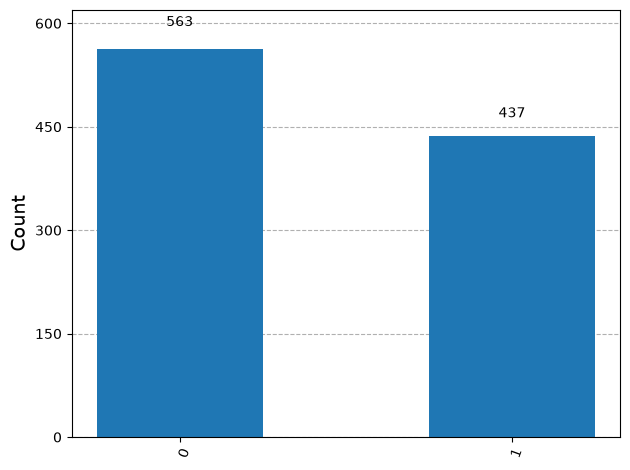

In [26]:
from qiskit.visualization import plot_histogram


statistics = v.sample_counts(1000)
plot_histogram(statistics)

## Perform operations with 'Operator' and 'Statevector' 

#### Unitary operations can be defined in Qiskit using the 'Operator' class

#### 'Operator' class also includes 'draw' method as in 'Statevector' class

In [28]:
from qiskit.quantum_info import Operator
from numpy import sqrt


Y = Operator([[0, -1.0j], [1.0j, 0]])
H = Operator([[1 / sqrt(2), 1 / sqrt(2)], [1 / sqrt(2), -1 / sqrt(2)]])
S = Operator([[1, 0], [0, 1.0j]])    #P_(Pi/2)
T = Operator([[1, 0], [0, (1 + 1.0j) / sqrt(2)]])   #P_(Pi/4)

display(T.draw("latex"))

<IPython.core.display.Latex object>

## 'evolve' method enables us to apply a unitary operation to a state vector

In [39]:
v = Statevector([1, 0])
display(v.draw("latex"))

v = v.evolve(H)
display(v.draw("latex"))
v = v.evolve(T)
display(v.draw("latex"))
v = v.evolve(H)
v = v.evolve(S)
v = v.evolve(Y)

display(v.draw("latex"))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

## We may define a Quantum Circuit (which, in this case, will simply be a sequence of unitary operations performed on a single qubit) as follows.

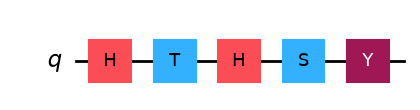

In [48]:
from qiskit import QuantumCircuit

circuit = QuantumCircuit(1)
#help(QuantumCircuit)
circuit.h(0)
circuit.t(0)
circuit.h(0)
circuit.s(0)
circuit.y(0)

display(circuit.draw("mpl"))  #short for matplotlib

## To get the unitary matrix corresponding to this circuit, use 'from_circuit' method from 'Operator' class

In [55]:
display(Operator.from_circuit(circuit).draw("latex"))

<IPython.core.display.Latex object>

## A quantum state operator can be evolved according to the sequence of operations described by the circuit

In [90]:
ket0 = Statevector([1,0])
v = ket0.evolve(circuit)
display(v.draw("latex"))

<IPython.core.display.Latex object>

## The following code simulates an experiment where the state obtained from the circuit above is measured with a standard basis measurement 4000 times (using a fresh copy of the state each time)

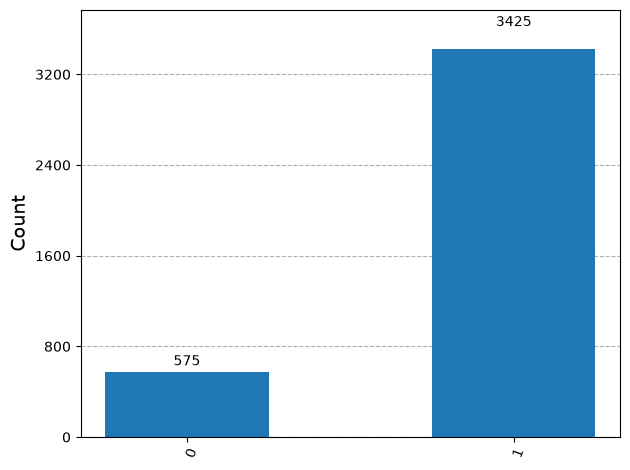

In [94]:
statistics = v.sample_counts(4000)
display(plot_histogram(statistics))